In [98]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn import model_selection 
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [99]:
photo_df_OK=pd.read_csv(f'14112025cam1_2026_01_23-16_09_39_OK.csv')
photo_df_OK.head(50)

,Date,Time,Measurement ID,Scene No.,Judge,P0.JG,P0.DY,P0.DT,P0.CR,P0.Y,...,I0.TH29,I0.CR30,I0.Y30,I0.TH30,I0.CR31,I0.Y31,I0.TH31,Z0.JG,Z0.J00,Z0.D00
0,2026/1/23,16:09:39,367800,0,0,0.0,-14.9635,0.0,72.9602,274.0365,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2026/1/23,16:09:40,367801,0,0,0.0,-10.5864,0.0,94.4776,278.4136,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2026/1/23,16:09:40,367802,0,0,0.0,3.6080,0.0,85.5970,292.6080,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2026/1/23,16:09:40,367803,0,0,0.0,-4.6356,0.0,95.8209,284.3644,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2026/1/23,16:09:41,367804,0,0,0.0,2.9776,0.0,95.7711,291.9776,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,2026/1/23,16:09:41,367805,0,0,0.0,-4.4281,0.0,91.0448,284.5719,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,2026/1/23,16:09:41,367806,0,0,0.0,3.7818,0.0,91.0697,292.7818,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,2026/1/23,16:09:42,367807,0,0,0.0,-8.1667,0.0,93.1343,280.8333,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,2026/1/23,16:09:42,367808,0,0,0.0,-3.1301,0.0,98.4080,285.8699,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,2026/1/23,16:09:42,367809,0,0,0.0,-5.4138,0.0,94.1791,283.5862,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Обработка данных НЕ Брак

In [100]:
photo_df_OK.describe()

,Measurement ID,Scene No.,Judge,P0.JG,P0.DY,P0.DT,P0.CR,P0.Y,P0.TH,P1.DY,...,I0.TH29,I0.CR30,I0.Y30,I0.TH30,I0.CR31,I0.Y31,I0.TH31,Z0.JG,Z0.J00,Z0.D00
count,1700.000000,1700.0,1700.000000,1700.000000,1700.000000,1700.0,1700.000000,1700.000000,1700.0,1700.000000,...,1700.0,1700.0,1700.0,1700.0,1700.0,1700.0,1700.0,1700.0,1700.0,1700.0
mean,368649.500000,0.0,-0.000588,-0.007059,0.074843,0.0,88.316535,288.632377,0.0,3.837343,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
std,490.892045,0.0,0.024254,0.083744,6.770374,0.0,10.140091,12.081636,0.0,3.478562,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
min,367800.000000,0.0,-1.000000,-1.000000,-42.961500,0.0,0.000000,0.000000,0.0,-23.576600,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,368224.750000,0.0,0.000000,0.000000,-3.965425,0.0,83.774875,284.904100,0.0,1.251200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
50%,368649.500000,0.0,0.000000,0.000000,-0.076100,0.0,92.114400,288.796450,0.0,3.109300,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
75%,369074.250000,0.0,0.000000,0.000000,4.516275,0.0,95.429125,293.516275,0.0,6.142250,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,369499.000000,0.0,0.000000,0.000000,23.414800,0.0,99.751200,312.414800,0.0,13.723600,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Text(0, 0.5, 'Кореляция  ')

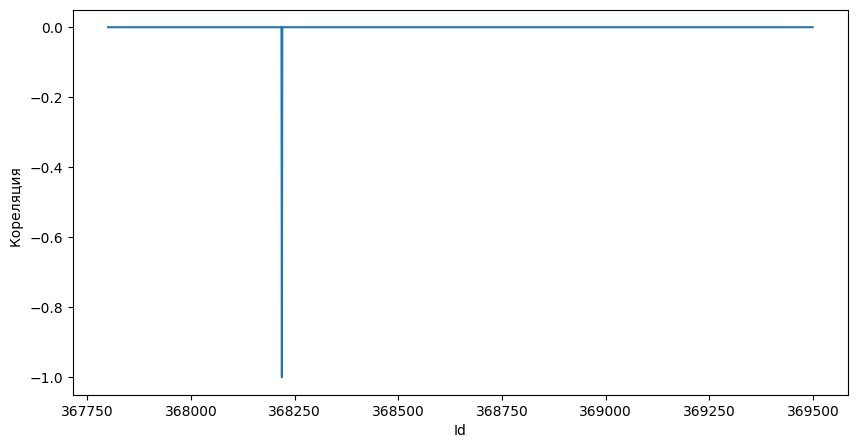

In [101]:


#photo_df = sns.load_dataset("penguins")

fig = plt.figure(figsize=(10, 5))

scatterplot = sns.lineplot(
    data=photo_df_OK,
    x='Measurement ID',
    #y='P0.TH',
    y='Judge',
    #hue='species',
    #s=100,
    #size='sex',
    sizes=(50, 300)

)
scatterplot.set_title('', fontsize=16)
scatterplot.set_xlabel('Id')
scatterplot.set_ylabel('Кореляция  ')

In [102]:

fig = px.scatter(photo_df_OK, x='Measurement ID', y="P0.CR")
fig.show()

In [103]:
fig = px.scatter(photo_df_OK, x='Measurement ID', y='P0.Y')
fig.show()


In [104]:
fig = px.scatter(photo_df_OK, x='Measurement ID', y='I0.CR0')
fig.show()

In [105]:
fig = px.scatter(photo_df_OK, x='Measurement ID', y='P0.TH')
fig.show()

# Предварительно находим ID помеченые браком и убираем их, то есть камера в предварительном режиме уже не обнаружила объект.

In [106]:

photo_df_I0CR00=photo_df_OK[photo_df_OK['Judge']==-1]
len(photo_df_I0CR00)
photo_df_I0CR00.info()
print(photo_df_I0CR00['Measurement ID'])

mask=photo_df_OK['Measurement ID'].isin(photo_df_I0CR00['Measurement ID'])
photo_df_OK.drop(photo_df_OK[mask].index,inplace=True)
photo_df_OK.info()

<class 'pandas.DataFrame'>
RangeIndex: 1 entries, 419 to 419
Columns: 115 entries, Date to Z0.D00
dtypes: float64(110), int64(3), str(2)
memory usage: 1.0 KB
419    368219
Name: Measurement ID, dtype: int64
<class 'pandas.DataFrame'>
Index: 1699 entries, 0 to 1699
Columns: 115 entries, Date to Z0.D00
dtypes: float64(110), int64(3), str(2)
memory usage: 1.5 MB


# Проверка(график), что отсутсвуют индексы с браком(Judge=-1)

Text(0, 0.5, 'Кореляция  ')

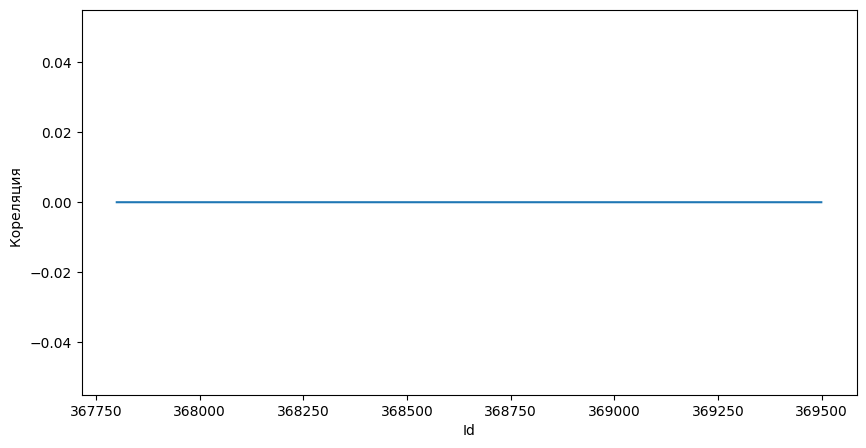

In [107]:


fig = plt.figure(figsize=(10, 5))

scatterplot = sns.lineplot(
    data=photo_df_OK,
    x='Measurement ID',
    #y='P0.TH',
    y='Judge',
    #hue='species',
    #s=100,
    #size='sex',
    sizes=(50, 300)

)
scatterplot.set_title('', fontsize=16)
scatterplot.set_xlabel('Id')
scatterplot.set_ylabel('Кореляция  ')

In [108]:

fig = px.scatter(photo_df_OK, x='Measurement ID', y="P0.CR")
fig.show()

# Проверка, что PO.CR(в данных это соответсвует коллерция форме крышки в камере), если есть уберём сразу

In [109]:

photo_df_P0CR00=photo_df_OK[photo_df_OK['P0.CR']==0]
len(photo_df_P0CR00)
photo_df_P0CR00.info()
print(photo_df_P0CR00['Measurement ID'])

mask=photo_df_OK['Measurement ID'].isin(photo_df_P0CR00['Measurement ID'])
photo_df_OK.drop(photo_df_OK[mask].index,inplace=True)
photo_df_OK.info()

<class 'pandas.DataFrame'>
Index: 1 entries, 1500 to 1500
Columns: 115 entries, Date to Z0.D00
dtypes: float64(110), int64(3), str(2)
memory usage: 928.0 bytes
1500    369300
Name: Measurement ID, dtype: int64
<class 'pandas.DataFrame'>
Index: 1698 entries, 0 to 1699
Columns: 115 entries, Date to Z0.D00
dtypes: float64(110), int64(3), str(2)
memory usage: 1.5 MB


In [110]:
photo_df_P0CR00=photo_df_OK[photo_df_OK['P0.JG']==-1.0]
len(photo_df_P0CR00)
photo_df_P0CR00.info()
print(photo_df_P0CR00['Measurement ID'])

mask=photo_df_OK['Measurement ID'].isin(photo_df_P0CR00['Measurement ID'])
photo_df_OK.drop(photo_df_OK[mask].index,inplace=True)
photo_df_OK.info()

<class 'pandas.DataFrame'>
Index: 10 entries, 223 to 1554
Columns: 115 entries, Date to Z0.D00
dtypes: float64(110), int64(3), str(2)
memory usage: 9.1 KB
223     368023
275     368075
301     368101
302     368102
384     368184
617     368417
782     368582
1331    369131
1361    369161
1554    369354
Name: Measurement ID, dtype: int64
<class 'pandas.DataFrame'>
Index: 1688 entries, 0 to 1699
Columns: 115 entries, Date to Z0.D00
dtypes: float64(110), int64(3), str(2)
memory usage: 1.5 MB


In [111]:
fig = px.scatter(photo_df_OK, x='Measurement ID', y="P0.CR")
fig.show()

In [112]:
fig = px.scatter(photo_df_OK, x='Measurement ID', y="I0.CR0")
fig.show()

# удаление столбцов где все значение =0

In [113]:

mask_columns=photo_df_OK.columns[(photo_df_OK == 0).all()]
mask_columns = [col for col in mask_columns if col != "Judge"]
print(mask_columns)
photo_df_OK.drop(columns=mask_columns,inplace=True)
photo_df_OK.drop(columns='I0.C',inplace=True)

photo_df_OK.describe()

['Scene No.', 'P0.JG', 'P0.DT', 'P0.TH', 'I0.TH0', 'I0.CR1', 'I0.Y1', 'I0.TH1', 'I0.CR2', 'I0.Y2', 'I0.TH2', 'I0.CR3', 'I0.Y3', 'I0.TH3', 'I0.CR4', 'I0.Y4', 'I0.TH4', 'I0.CR5', 'I0.Y5', 'I0.TH5', 'I0.CR6', 'I0.Y6', 'I0.TH6', 'I0.CR7', 'I0.Y7', 'I0.TH7', 'I0.CR8', 'I0.Y8', 'I0.TH8', 'I0.CR9', 'I0.Y9', 'I0.TH9', 'I0.CR10', 'I0.Y10', 'I0.TH10', 'I0.CR11', 'I0.Y11', 'I0.TH11', 'I0.CR12', 'I0.Y12', 'I0.TH12', 'I0.CR13', 'I0.Y13', 'I0.TH13', 'I0.CR14', 'I0.Y14', 'I0.TH14', 'I0.CR15', 'I0.Y15', 'I0.TH15', 'I0.CR16', 'I0.Y16', 'I0.TH16', 'I0.CR17', 'I0.Y17', 'I0.TH17', 'I0.CR18', 'I0.Y18', 'I0.TH18', 'I0.CR19', 'I0.Y19', 'I0.TH19', 'I0.CR20', 'I0.Y20', 'I0.TH20', 'I0.CR21', 'I0.Y21', 'I0.TH21', 'I0.CR22', 'I0.Y22', 'I0.TH22', 'I0.CR23', 'I0.Y23', 'I0.TH23', 'I0.CR24', 'I0.Y24', 'I0.TH24', 'I0.CR25', 'I0.Y25', 'I0.TH25', 'I0.CR26', 'I0.Y26', 'I0.TH26', 'I0.CR27', 'I0.Y27', 'I0.TH27', 'I0.CR28', 'I0.Y28', 'I0.TH28', 'I0.CR29', 'I0.Y29', 'I0.TH29', 'I0.CR30', 'I0.Y30', 'I0.TH30', 'I0.CR31', 'I0.Y

,Measurement ID,Judge,P0.DY,P0.CR,P0.Y,P1.DY,P1.CR,P1.Y,P1.TH,I0.CR0,I0.Y0
count,1688.000000,1688.0,1688.000000,1688.000000,1688.000000,1688.000000,1688.000000,1688.000000,1688.000000,1688.000000,1688.000000
mean,368650.178318,0.0,0.075375,88.605919,289.075375,3.957877,99.094939,403.457877,0.193705,93.388191,392.860571
std,490.707369,0.0,6.794408,9.403126,6.794408,3.141071,1.590246,3.141071,0.922155,4.255135,0.383932
min,367800.000000,0.0,-42.961500,60.124400,246.038500,-2.364300,86.861300,397.135700,-5.691500,75.897400,391.481200
25%,368227.750000,0.0,-3.987750,84.079600,285.012250,1.287500,98.905100,400.787500,-0.229550,90.769200,392.668975
50%,368651.500000,0.0,-0.133350,92.189100,288.866650,3.121900,100.000000,402.621900,-0.107000,94.139200,392.913350
75%,369073.250000,0.0,4.542800,95.447800,293.542800,6.158500,100.000000,405.658500,0.104200,96.959700,393.130175
max,369499.000000,0.0,23.414800,99.751200,312.414800,13.723600,100.000000,413.223600,3.713900,100.000000,393.959900


In [114]:
photo_df_OK = photo_df_OK.reset_index(drop=True)
photo_df_OK.info()

<class 'pandas.DataFrame'>
RangeIndex: 1688 entries, 0 to 1687
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            1688 non-null   str    
 1   Time            1688 non-null   str    
 2   Measurement ID  1688 non-null   int64  
 3   Judge           1688 non-null   int64  
 4   P0.DY           1688 non-null   float64
 5   P0.CR           1688 non-null   float64
 6   P0.Y            1688 non-null   float64
 7   P1.DY           1688 non-null   float64
 8   P1.CR           1688 non-null   float64
 9   P1.Y            1688 non-null   float64
 10  P1.TH           1688 non-null   float64
 11  I0.CR0          1688 non-null   float64
 12  I0.Y0           1688 non-null   float64
dtypes: float64(9), int64(2), str(2)
memory usage: 171.6 KB


In [115]:
fig = px.scatter(photo_df_OK, x='Measurement ID', y=['P0.DY','P0.CR','P0.Y','P1.DY',"P1.CR",'P1.Y','P1.TH','I0.CR0','I0.Y0'])
fig.show()


In [116]:
photo_df_OK.describe()

,Measurement ID,Judge,P0.DY,P0.CR,P0.Y,P1.DY,P1.CR,P1.Y,P1.TH,I0.CR0,I0.Y0
count,1688.000000,1688.0,1688.000000,1688.000000,1688.000000,1688.000000,1688.000000,1688.000000,1688.000000,1688.000000,1688.000000
mean,368650.178318,0.0,0.075375,88.605919,289.075375,3.957877,99.094939,403.457877,0.193705,93.388191,392.860571
std,490.707369,0.0,6.794408,9.403126,6.794408,3.141071,1.590246,3.141071,0.922155,4.255135,0.383932
min,367800.000000,0.0,-42.961500,60.124400,246.038500,-2.364300,86.861300,397.135700,-5.691500,75.897400,391.481200
25%,368227.750000,0.0,-3.987750,84.079600,285.012250,1.287500,98.905100,400.787500,-0.229550,90.769200,392.668975
50%,368651.500000,0.0,-0.133350,92.189100,288.866650,3.121900,100.000000,402.621900,-0.107000,94.139200,392.913350
75%,369073.250000,0.0,4.542800,95.447800,293.542800,6.158500,100.000000,405.658500,0.104200,96.959700,393.130175
max,369499.000000,0.0,23.414800,99.751200,312.414800,13.723600,100.000000,413.223600,3.713900,100.000000,393.959900


# Здесь дропаем признаки которые точно не нужны, время даты и т.п.
Так же убираем P0.Y и P1.Y эти признаки определяют на какой высоте найдены признаки в изображение камеры, что пагубно повлияет на обобщающей способности модели. При малейшем изменение высоты колпака будет давать сильные изменения и будет требовать переобучения модели. Полезней использовать такие параметры как разница обнаружения от эталона PO.DY и P1.DY. А ведь может бутылка и выше стать и фокус сместиться. Корреляция так же уберём

In [117]:
photo_df_OK.drop(columns=["Measurement ID",'Date','Time','P0.Y','P1.Y','I0.CR0','I0.Y0'],inplace=True)
photo_df_OK.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.TH
count,1688.0,1688.000000,1688.000000,1688.000000,1688.000000,1688.000000
mean,0.0,0.075375,88.605919,3.957877,99.094939,0.193705
std,0.0,6.794408,9.403126,3.141071,1.590246,0.922155
min,0.0,-42.961500,60.124400,-2.364300,86.861300,-5.691500
25%,0.0,-3.987750,84.079600,1.287500,98.905100,-0.229550
50%,0.0,-0.133350,92.189100,3.121900,100.000000,-0.107000
75%,0.0,4.542800,95.447800,6.158500,100.000000,0.104200
max,0.0,23.414800,99.751200,13.723600,100.000000,3.713900


[[ 1.      0.5004  0.6469  0.3666 -0.0081]
 [ 0.5004  1.      0.3881  0.3312 -0.0107]
 [ 0.6469  0.3881  1.      0.2881 -0.0693]
 [ 0.3666  0.3312  0.2881  1.     -0.1542]
 [-0.0081 -0.0107 -0.0693 -0.1542  1.    ]]
(5, 5)


<Axes: >

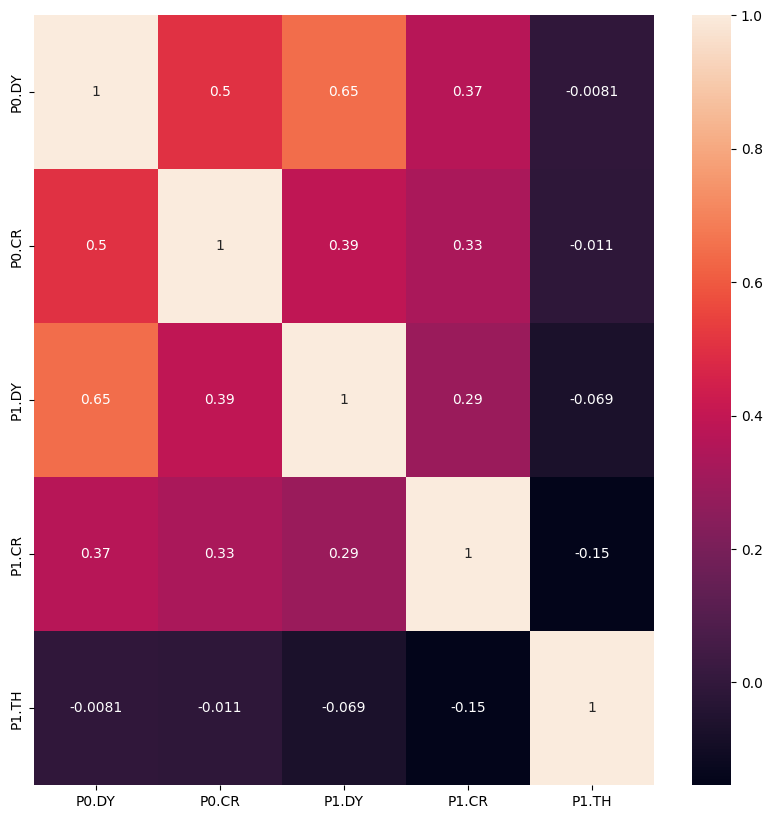

In [118]:




photo_df_OK.head()
#print(photo_df)
#y=df['Performance Index']

#n=len(photo_df['P0.Y'])

X_future=photo_df_OK.drop(columns='Judge')
X=photo_df_OK.drop(columns='Judge').values

#cтандартизация данных таблицы
X_std=(X-X.mean(axis=0))/X.std(axis=0,ddof=1)

#стандартизация вектора столбцов

X_std_cov=(X_std.T@X_std)/(X_std.shape[0]-1)




print(X_std_cov)
print(X_std_cov.shape)
plt.figure(figsize=(10, 10))
sns.heatmap(X_std_cov,annot=True,xticklabels=X_future.columns,
            yticklabels=X_future.columns)




In [119]:
fig = px.scatter(photo_df_OK, y=['P0.DY','P0.CR','P1.DY',"P1.CR",'P1.TH'])
fig.show()


In [120]:
fig = px.box(photo_df_OK, y=['P0.DY','P0.CR','P1.DY',"P1.CR",'P1.TH','I0.CR0','I0.Y0'],orientation='v')
fig.show()


только для не брака

In [121]:
photo_df_P0DY=photo_df_OK[photo_df_OK['P0.DY']<-30]


mask=photo_df_OK['P0.DY'].isin(photo_df_P0DY['P0.DY'])
photo_df_OK.drop(photo_df_OK[mask].index,inplace=True)
photo_df_OK.info()

<class 'pandas.DataFrame'>
Index: 1687 entries, 0 to 1687
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Judge   1687 non-null   int64  
 1   P0.DY   1687 non-null   float64
 2   P0.CR   1687 non-null   float64
 3   P1.DY   1687 non-null   float64
 4   P1.CR   1687 non-null   float64
 5   P1.TH   1687 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 92.3 KB


In [122]:
fig = px.box(photo_df_OK, y=['P0.DY','P0.CR','P1.DY',"P1.CR",'P1.TH'],orientation='v')
fig.show()


# Z обрезание данных не брака(очищаем от выбросов)

In [123]:
def  outliers_z_score_mod(data, feature, log_scale=False,left=3,right=3):
    if log_scale:
        x = np.log(data[feature]+1)
    else:
        x = data[feature]
    mu = x.mean()
    sigma = x.std()
    lower_bound = mu - left * sigma
    upper_bound = mu + right * sigma
    outliers = data[(x < lower_bound) | (x > upper_bound)]
    cleaned = data[(x >= lower_bound) & (x <= upper_bound)]
    return outliers, cleaned

In [124]:
for col in photo_df_OK.columns:
    outliers, photo_df_OK = outliers_z_score_mod(photo_df_OK, col ,left=1.5,right=1.5) #Здесь ужесточим границу
    print(f'Число выбросов по методу z-отклонения в колонке {col}: {outliers.shape[0]}')
    print(f'Результирующее число записей: {photo_df_OK.shape[0]}')

Число выбросов по методу z-отклонения в колонке Judge: 0
Результирующее число записей: 1687
Число выбросов по методу z-отклонения в колонке P0.DY: 264
Результирующее число записей: 1423
Число выбросов по методу z-отклонения в колонке P0.CR: 155
Результирующее число записей: 1268
Число выбросов по методу z-отклонения в колонке P1.DY: 145
Результирующее число записей: 1123
Число выбросов по методу z-отклонения в колонке P1.CR: 91
Результирующее число записей: 1032
Число выбросов по методу z-отклонения в колонке P1.TH: 245
Результирующее число записей: 787


In [125]:
fig = px.box(photo_df_OK, y=['P0.DY','P0.CR','P1.DY',"P1.CR",'P1.TH'],orientation='v')
fig.show()

In [126]:
photo_df_OK.info()

<class 'pandas.DataFrame'>
Index: 787 entries, 3 to 1687
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Judge   787 non-null    int64  
 1   P0.DY   787 non-null    float64
 2   P0.CR   787 non-null    float64
 3   P1.DY   787 non-null    float64
 4   P1.CR   787 non-null    float64
 5   P1.TH   787 non-null    float64
dtypes: float64(5), int64(1)
memory usage: 43.0 KB


In [127]:
photo_df_OK.value_counts()

Judge  P0.DY    P0.CR    P1.DY   P1.CR     P1.TH  
0      -4.6356  95.8209  4.2836  100.0000   0.0272    1
        2.9776  95.7711  8.0151  100.0000  -0.5005    1
        3.7818  91.0697  7.3902  98.5401    0.0975    1
       -3.1301  98.4080  4.0363  100.0000   0.0525    1
       -5.4138  94.1791  0.1063  99.6350   -0.2644    1
                                                     ..
       -1.0258  96.4925  5.7595  98.2117   -0.1000    1
        5.4188  88.9303  0.6344  100.0000  -0.1828    1
        0.4859  97.8856  5.1734  100.0000  -0.1662    1
       -3.8289  96.0199  3.6421  100.0000  -0.2679    1
        5.1848  93.1343  2.6988  99.6350   -0.3454    1
Name: count, Length: 787, dtype: int64

# Обработка данных брака (на камеру 1 было залогировано два файла)

In [128]:
photo_df_NG_part1=pd.read_csv(f"14112025cam1_2026_01_27-09_15_10_NG_part1.csv")
photo_df_NG_part1.info()

<class 'pandas.DataFrame'>
RangeIndex: 466 entries, 0 to 465
Columns: 115 entries, Date to Z0.D00
dtypes: float64(110), int64(3), str(2)
memory usage: 418.8 KB


In [129]:
photo_df_NG_part2=pd.read_csv(f"14112025cam1_2026_01_27-09_44_53_NG_part2.csv")
photo_df_NG_part2.info()

<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Columns: 115 entries, Date to Z0.D00
dtypes: float64(110), int64(3), str(2)
memory usage: 151.1 KB


# Объединение двух файлов брака

In [130]:
photo_df_NG=pd.concat([photo_df_NG_part1,photo_df_NG_part2],ignore_index=True)
photo_df_NG.info()

<class 'pandas.DataFrame'>
RangeIndex: 634 entries, 0 to 633
Columns: 115 entries, Date to Z0.D00
dtypes: float64(110), int64(3), str(2)
memory usage: 569.7 KB


# Обработка информации по браку

In [131]:
photo_df_NG.value_counts()

Date       Time      Measurement ID  Scene No.  Judge  P0.JG  P0.DY     P0.DT  P0.CR    P0.Y      P0.TH  P1.DY    P1.CR     P1.Y      P1.TH    I0.C  I0.CR0   I0.Y0     I0.TH0  I0.CR1  I0.Y1  I0.TH1  I0.CR2  I0.Y2  I0.TH2  I0.CR3  I0.Y3  I0.TH3  I0.CR4  I0.Y4  I0.TH4  I0.CR5  I0.Y5  I0.TH5  I0.CR6  I0.Y6  I0.TH6  I0.CR7  I0.Y7  I0.TH7  I0.CR8  I0.Y8  I0.TH8  I0.CR9  I0.Y9  I0.TH9  I0.CR10  I0.Y10  I0.TH10  I0.CR11  I0.Y11  I0.TH11  I0.CR12  I0.Y12  I0.TH12  I0.CR13  I0.Y13  I0.TH13  I0.CR14  I0.Y14  I0.TH14  I0.CR15  I0.Y15  I0.TH15  I0.CR16  I0.Y16  I0.TH16  I0.CR17  I0.Y17  I0.TH17  I0.CR18  I0.Y18  I0.TH18  I0.CR19  I0.Y19  I0.TH19  I0.CR20  I0.Y20  I0.TH20  I0.CR21  I0.Y21  I0.TH21  I0.CR22  I0.Y22  I0.TH22  I0.CR23  I0.Y23  I0.TH23  I0.CR24  I0.Y24  I0.TH24  I0.CR25  I0.Y25  I0.TH25  I0.CR26  I0.Y26  I0.TH26  I0.CR27  I0.Y27  I0.TH27  I0.CR28  I0.Y28  I0.TH28  I0.CR29  I0.Y29  I0.TH29  I0.CR30  I0.Y30  I0.TH30  I0.CR31  I0.Y31  I0.TH31  Z0.JG  Z0.J00  Z0.D00
2026/1/27  09:15:10  10

In [132]:
photo_df_NG['Judge']=-1
photo_df_NG.value_counts()

Date       Time      Measurement ID  Scene No.  Judge  P0.JG  P0.DY     P0.DT  P0.CR    P0.Y      P0.TH  P1.DY    P1.CR     P1.Y      P1.TH    I0.C  I0.CR0   I0.Y0     I0.TH0  I0.CR1  I0.Y1  I0.TH1  I0.CR2  I0.Y2  I0.TH2  I0.CR3  I0.Y3  I0.TH3  I0.CR4  I0.Y4  I0.TH4  I0.CR5  I0.Y5  I0.TH5  I0.CR6  I0.Y6  I0.TH6  I0.CR7  I0.Y7  I0.TH7  I0.CR8  I0.Y8  I0.TH8  I0.CR9  I0.Y9  I0.TH9  I0.CR10  I0.Y10  I0.TH10  I0.CR11  I0.Y11  I0.TH11  I0.CR12  I0.Y12  I0.TH12  I0.CR13  I0.Y13  I0.TH13  I0.CR14  I0.Y14  I0.TH14  I0.CR15  I0.Y15  I0.TH15  I0.CR16  I0.Y16  I0.TH16  I0.CR17  I0.Y17  I0.TH17  I0.CR18  I0.Y18  I0.TH18  I0.CR19  I0.Y19  I0.TH19  I0.CR20  I0.Y20  I0.TH20  I0.CR21  I0.Y21  I0.TH21  I0.CR22  I0.Y22  I0.TH22  I0.CR23  I0.Y23  I0.TH23  I0.CR24  I0.Y24  I0.TH24  I0.CR25  I0.Y25  I0.TH25  I0.CR26  I0.Y26  I0.TH26  I0.CR27  I0.Y27  I0.TH27  I0.CR28  I0.Y28  I0.TH28  I0.CR29  I0.Y29  I0.TH29  I0.CR30  I0.Y30  I0.TH30  I0.CR31  I0.Y31  I0.TH31  Z0.JG  Z0.J00  Z0.D00
2026/1/27  09:15:10  10

In [133]:
photo_df_NG.nunique()
photo_df_NG.drop(columns=["Measurement ID",'Date','Time','Scene No.','P0.JG',	'Z0.JG',	'Z0.J00',	'Z0.D00'],inplace=True)

In [134]:
photo_df_NG.nunique()

Judge        1
P0.DY      421
P0.DT        1
P0.CR      397
P0.Y       439
          ... 
I0.Y30       1
I0.TH30      1
I0.CR31      1
I0.Y31       1
I0.TH31      1
Length: 107, dtype: int64

In [135]:
#удаление столбцов где все значение =0
mask_columns=photo_df_NG.columns[(photo_df_NG == 0).all()]
mask_columns = [col for col in mask_columns if col != "Judge"]
print(mask_columns)
photo_df_NG.drop(columns=mask_columns,inplace=True)
photo_df_NG.drop(columns='I0.C',inplace=True)
photo_df_NG.describe()

['P0.DT', 'P0.TH', 'I0.TH0', 'I0.CR1', 'I0.Y1', 'I0.TH1', 'I0.CR2', 'I0.Y2', 'I0.TH2', 'I0.CR3', 'I0.Y3', 'I0.TH3', 'I0.CR4', 'I0.Y4', 'I0.TH4', 'I0.CR5', 'I0.Y5', 'I0.TH5', 'I0.CR6', 'I0.Y6', 'I0.TH6', 'I0.CR7', 'I0.Y7', 'I0.TH7', 'I0.CR8', 'I0.Y8', 'I0.TH8', 'I0.CR9', 'I0.Y9', 'I0.TH9', 'I0.CR10', 'I0.Y10', 'I0.TH10', 'I0.CR11', 'I0.Y11', 'I0.TH11', 'I0.CR12', 'I0.Y12', 'I0.TH12', 'I0.CR13', 'I0.Y13', 'I0.TH13', 'I0.CR14', 'I0.Y14', 'I0.TH14', 'I0.CR15', 'I0.Y15', 'I0.TH15', 'I0.CR16', 'I0.Y16', 'I0.TH16', 'I0.CR17', 'I0.Y17', 'I0.TH17', 'I0.CR18', 'I0.Y18', 'I0.TH18', 'I0.CR19', 'I0.Y19', 'I0.TH19', 'I0.CR20', 'I0.Y20', 'I0.TH20', 'I0.CR21', 'I0.Y21', 'I0.TH21', 'I0.CR22', 'I0.Y22', 'I0.TH22', 'I0.CR23', 'I0.Y23', 'I0.TH23', 'I0.CR24', 'I0.Y24', 'I0.TH24', 'I0.CR25', 'I0.Y25', 'I0.TH25', 'I0.CR26', 'I0.Y26', 'I0.TH26', 'I0.CR27', 'I0.Y27', 'I0.TH27', 'I0.CR28', 'I0.Y28', 'I0.TH28', 'I0.CR29', 'I0.Y29', 'I0.TH29', 'I0.CR30', 'I0.Y30', 'I0.TH30', 'I0.CR31', 'I0.Y31', 'I0.TH31']


,Judge,P0.DY,P0.CR,P0.Y,P1.DY,P1.CR,P1.Y,P1.TH,I0.CR0,I0.Y0
count,634.0,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000
mean,-1.0,-27.885282,54.819712,177.033722,4.091830,69.318255,297.663243,0.794723,80.515478,356.396476
std,0.0,22.618117,35.798063,113.113531,11.168568,42.162028,179.204386,3.118230,23.736022,94.690263
min,-1.0,-61.445400,0.000000,0.000000,-65.201300,0.000000,0.000000,-7.734400,0.000000,0.000000
25%,-1.0,-47.871725,0.000000,0.000000,0.000000,0.000000,0.000000,-0.357775,74.331475,346.258925
50%,-1.0,-31.630800,71.629350,238.129600,7.298600,93.065700,406.798600,0.000000,87.692300,392.686100
75%,-1.0,0.000000,80.186575,253.272500,9.863600,99.635000,409.363600,3.517125,96.584250,393.300925
max,-1.0,20.345500,98.059700,309.345500,18.893200,100.000000,418.393200,9.088800,99.707000,414.959000


In [136]:
for col in photo_df_NG.columns:
    outliers, photo_df_NG = outliers_z_score_mod(photo_df_NG, col ,left=3,right=3) #Здесь ужесточим границу
    print(f'Число выбросов по методу z-отклонения в колонке {col}: {outliers.shape[0]}')
    print(f'Результирующее число записей: {photo_df_NG.shape[0]}')

Число выбросов по методу z-отклонения в колонке Judge: 0
Результирующее число записей: 634
Число выбросов по методу z-отклонения в колонке P0.DY: 0
Результирующее число записей: 634
Число выбросов по методу z-отклонения в колонке P0.CR: 0
Результирующее число записей: 634
Число выбросов по методу z-отклонения в колонке P0.Y: 0
Результирующее число записей: 634
Число выбросов по методу z-отклонения в колонке P1.DY: 17
Результирующее число записей: 617
Число выбросов по методу z-отклонения в колонке P1.CR: 0
Результирующее число записей: 617
Число выбросов по методу z-отклонения в колонке P1.Y: 0
Результирующее число записей: 617
Число выбросов по методу z-отклонения в колонке P1.TH: 0
Результирующее число записей: 617
Число выбросов по методу z-отклонения в колонке I0.CR0: 39
Результирующее число записей: 578
Число выбросов по методу z-отклонения в колонке I0.Y0: 0
Результирующее число записей: 578


# Контрольный график признаков NG

In [137]:
fig = px.box(photo_df_NG, y=['P0.DY','P0.CR','P1.DY',"P1.CR",'P1.TH'],orientation='v',title='Брак')
fig.show()


In [138]:
fig = px.box(photo_df_OK, y=['P0.DY','P0.CR','P1.DY',"P1.CR",'P1.TH'],orientation='v',title='НЕ Брак')
fig.show()


# Приводим количество колонок в DF брака и не брака к одному количеству.

In [139]:
photo_df_OK.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.TH
count,787.0,787.000000,787.000000,787.000000,787.000000,787.000000
mean,0.0,0.584639,92.855892,3.825353,99.660354,-0.109184
std,0.0,4.249482,4.842174,2.319002,0.605587,0.278620
min,0.0,-9.901600,78.184100,-0.212600,97.189800,-0.545100
25%,0.0,-2.788300,91.044800,1.965300,99.635000,-0.239850
50%,0.0,0.514300,93.930300,3.434200,100.000000,-0.145200
75%,0.0,3.939050,96.293500,5.612450,100.000000,-0.042300
max,0.0,10.006100,99.751200,8.402400,100.000000,1.562500


In [140]:
photo_df_NG.describe()

,Judge,P0.DY,P0.CR,P0.Y,P1.DY,P1.CR,P1.Y,P1.TH,I0.CR0,I0.Y0
count,578.0,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000
mean,-1.0,-30.505682,59.521856,191.675563,5.972943,73.358863,315.579664,0.847063,85.947437,379.372233
std,0.0,21.899750,33.511490,105.176384,6.406915,40.066450,170.239132,3.226831,12.177035,26.138405
min,-1.0,-61.445400,0.000000,0.000000,-27.617800,0.000000,0.000000,-7.734400,50.805900,322.742200
25%,-1.0,-49.444750,58.718925,228.557350,0.000000,76.678800,392.429350,-0.461925,76.849800,391.355475
50%,-1.0,-34.315000,73.208950,240.671250,7.737450,95.109500,407.237450,0.000000,90.201450,392.773300
75%,-1.0,0.000000,81.424150,255.133625,10.043800,100.000000,409.543800,3.577675,96.813200,393.335600
max,-1.0,20.345500,98.059700,309.345500,18.893200,100.000000,418.393200,8.250000,99.707000,414.959000


In [141]:

photo_df_NG.drop(columns=['I0.CR0','I0.Y0','P0.Y','P1.Y'],inplace=True)
print(photo_df_NG.info())
print(photo_df_OK.info())


<class 'pandas.DataFrame'>
Index: 578 entries, 0 to 633
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Judge   578 non-null    int64  
 1   P0.DY   578 non-null    float64
 2   P0.CR   578 non-null    float64
 3   P1.DY   578 non-null    float64
 4   P1.CR   578 non-null    float64
 5   P1.TH   578 non-null    float64
dtypes: float64(5), int64(1)
memory usage: 31.6 KB
None
<class 'pandas.DataFrame'>
Index: 787 entries, 3 to 1687
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Judge   787 non-null    int64  
 1   P0.DY   787 non-null    float64
 2   P0.CR   787 non-null    float64
 3   P1.DY   787 non-null    float64
 4   P1.CR   787 non-null    float64
 5   P1.TH   787 non-null    float64
dtypes: float64(5), int64(1)
memory usage: 43.0 KB
None


# Объединяем в общий DataFrame брак и не брак

In [142]:
photo_df=pd.concat([photo_df_OK,photo_df_NG],ignore_index=True)
photo_df.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.TH
count,1365.000000,1365.000000,1365.000000,1365.000000,1365.000000,1365.000000
mean,-0.423443,-12.580347,78.740820,4.734736,88.523166,0.295733
std,0.494285,21.200140,27.568959,4.646518,29.125699,2.161670
min,-1.000000,-61.445400,0.000000,-27.617800,0.000000,-7.734400
25%,-1.000000,-29.518500,76.218900,1.847100,97.445300,-0.250900
50%,0.000000,-1.923100,89.527400,4.675800,99.890500,-0.100000
75%,0.000000,1.683200,94.701500,7.719100,100.000000,0.045300
max,0.000000,20.345500,99.751200,18.893200,100.000000,8.250000


In [143]:
photo_df.reset_index()

,index,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.TH
0,0,0,-4.6356,95.8209,4.2836,100.0000,0.0272
1,1,0,2.9776,95.7711,8.0151,100.0000,-0.5005
2,2,0,3.7818,91.0697,7.3902,98.5401,0.0975
3,3,0,-3.1301,98.4080,4.0363,100.0000,0.0525
4,4,0,-5.4138,94.1791,0.1063,99.6350,-0.2644
...,...,...,...,...,...,...,...
1360,1360,-1,2.3332,62.3632,8.2996,100.0000,-0.5114
1361,1361,-1,-12.4958,65.4975,11.2933,100.0000,3.4012
1362,1362,-1,-29.0170,68.5075,11.1672,100.0000,4.1335
1363,1363,-1,-59.0549,69.5771,11.8758,76.7883,-3.0099


In [144]:
photo_df = photo_df.sample(frac=1,random_state=15).reset_index(drop=True)
photo_df.reset_index()
#import math

#photo_df['P1.THSin'] = photo_df['P1.TH'].apply(lambda x: abs(math.sin(np.radians(x))))

,index,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.TH
0,0,0,-6.9446,88.3831,2.1828,100.0000,-0.1512
1,1,-1,-53.2703,73.3333,8.1618,87.5912,-1.7527
2,2,0,-2.1753,92.3881,1.3782,100.0000,-0.0542
3,3,-1,-52.4574,76.9900,0.7393,97.4453,-3.8839
4,4,0,5.9809,97.8358,2.8715,99.9635,-0.1467
...,...,...,...,...,...,...,...
1360,1360,-1,-18.1858,68.5323,10.8230,98.9051,4.0133
1361,1361,0,-3.0799,95.4229,5.3702,99.6350,-0.3007
1362,1362,0,5.4925,93.2338,3.1463,100.0000,0.0000
1363,1363,0,-1.1032,93.9303,3.2471,100.0000,-0.2461


# Добавление признака "sin" угла крышки относительно кромки по модулю

In [145]:
angle_rad = np.radians(photo_df['P1.TH'])
photo_df['P1.angle_sin'] = abs(np.sin(angle_rad))
photo_df['P0.CR']=photo_df['P0.CR']/100 #Здесь нормализируем к 0-1 корееляция фиксированая от 0 100
photo_df['P1.CR']=photo_df['P1.CR']/100
photo_df['P1.DY']=(photo_df['P1.DY']-(-100))/(100-(-100))#Здесь уже DY фактически может и 100 и + 100 приводим по формуле
photo_df['P0.DY']=(photo_df['P0.DY']-(-100))/(100-(-100))#Здесь уже DY фактически может и 100 и + 100 приводим по формуле

#df['angle_cos'] = np.cos(angle_rad)
#angle_rad = np.radians(photo_df['P1.TH'])
#photo_df['P1.angle_sin'] = abs(np.sin(angle_rad))

In [146]:
photo_df.reset_index()

,index,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.TH,P1.angle_sin
0,0,0,0.465277,0.883831,0.510914,1.000000,-0.1512,0.002639
1,1,-1,0.233649,0.733333,0.540809,0.875912,-1.7527,0.030586
2,2,0,0.489124,0.923881,0.506891,1.000000,-0.0542,0.000946
3,3,-1,0.237713,0.769900,0.503696,0.974453,-3.8839,0.067735
4,4,0,0.529905,0.978358,0.514358,0.999635,-0.1467,0.002560
...,...,...,...,...,...,...,...,...
1360,1360,-1,0.409071,0.685323,0.554115,0.989051,4.0133,0.069988
1361,1361,0,0.484601,0.954229,0.526851,0.996350,-0.3007,0.005248
1362,1362,0,0.527463,0.932338,0.515732,1.000000,0.0000,0.000000
1363,1363,0,0.494484,0.939303,0.516236,1.000000,-0.2461,0.004295


In [147]:
#Убираем признак Угол тангенс  P1.TH
photo_df.drop(columns=['P1.TH'],inplace=True)
#photo_df.dropna(inplace=True,axis=1)
photo_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1365 entries, 0 to 1364
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Judge         1365 non-null   int64  
 1   P0.DY         1365 non-null   float64
 2   P0.CR         1365 non-null   float64
 3   P1.DY         1365 non-null   float64
 4   P1.CR         1365 non-null   float64
 5   P1.angle_sin  1365 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 64.1 KB


[[ 1.      0.7249  0.5976 -0.2285  0.4464 -0.5914]
 [ 0.7249  1.      0.0346 -0.4294 -0.077  -0.6812]
 [ 0.5976  0.0346  1.      0.2605  0.9073 -0.0518]
 [-0.2285 -0.4294  0.2605  1.      0.3146  0.3222]
 [ 0.4464 -0.077   0.9073  0.3146  1.      0.1261]
 [-0.5914 -0.6812 -0.0518  0.3222  0.1261  1.    ]]
(6, 6)


<Axes: >

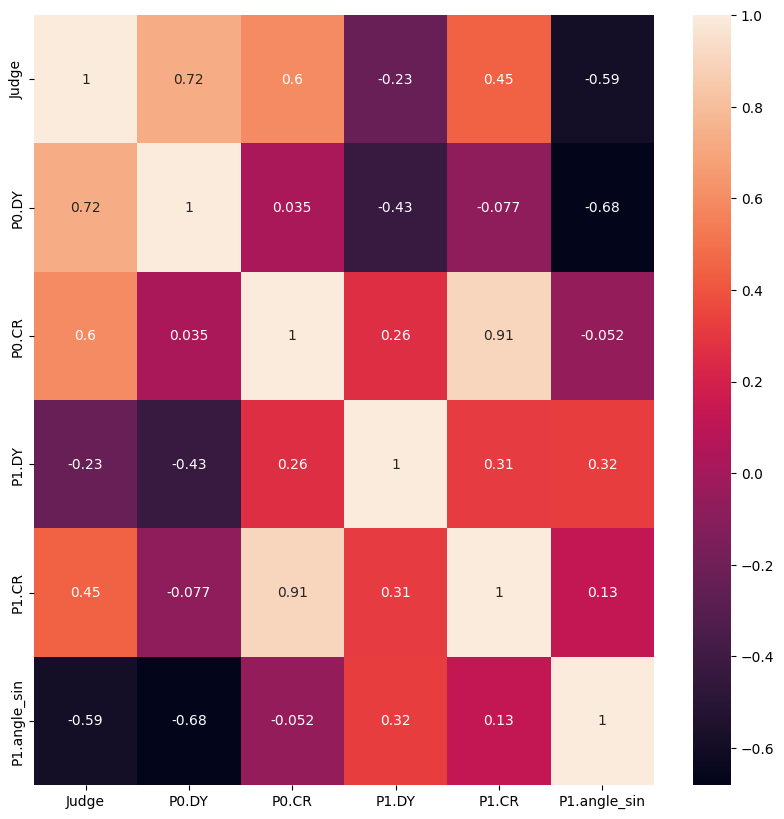

In [148]:



photo_df.head()



X=photo_df.values

#cтандартизация данных таблицы
X_std=(X-X.mean(axis=0))/X.std(axis=0,ddof=1)

X_std_cov=(X_std.T@X_std)/(X_std.shape[0]-1)


print(X_std_cov)
print(X_std_cov.shape)
plt.figure(figsize=(10, 10))
sns.heatmap(X_std_cov,annot=True,xticklabels=photo_df.columns,
            yticklabels=photo_df.columns)


# Итоговое распределение данных

Проверка распределения

АНАЛИЗ РАСПРЕДЕЛЕНИЯ КЛАССОВ
Текущая бинаризация (Judge == 0):
  Класс 1 (Judge == 0): 787 примеров (57.7%)
  Класс 0 (Judge != 0): 578 примеров (42.3%)

Альтернативная бинаризация (Judge > 0):
  Класс 1 (Judge > 0): 0 примеров (0.0%)
  Класс 0 (Judge ≤ 0): 1365 примеров (100.0%)

Статистика значений Judge:
  Минимум: -1
  Максимум: 0
  Среднее: -0.42
  Медиана: 0.00
  Уникальные значения: 2

Количество Judge = 0: 787 (57.7%)
Количество Judge > 0: 0 (0.0%)
Количество Judge < 0: 578 (42.3%)


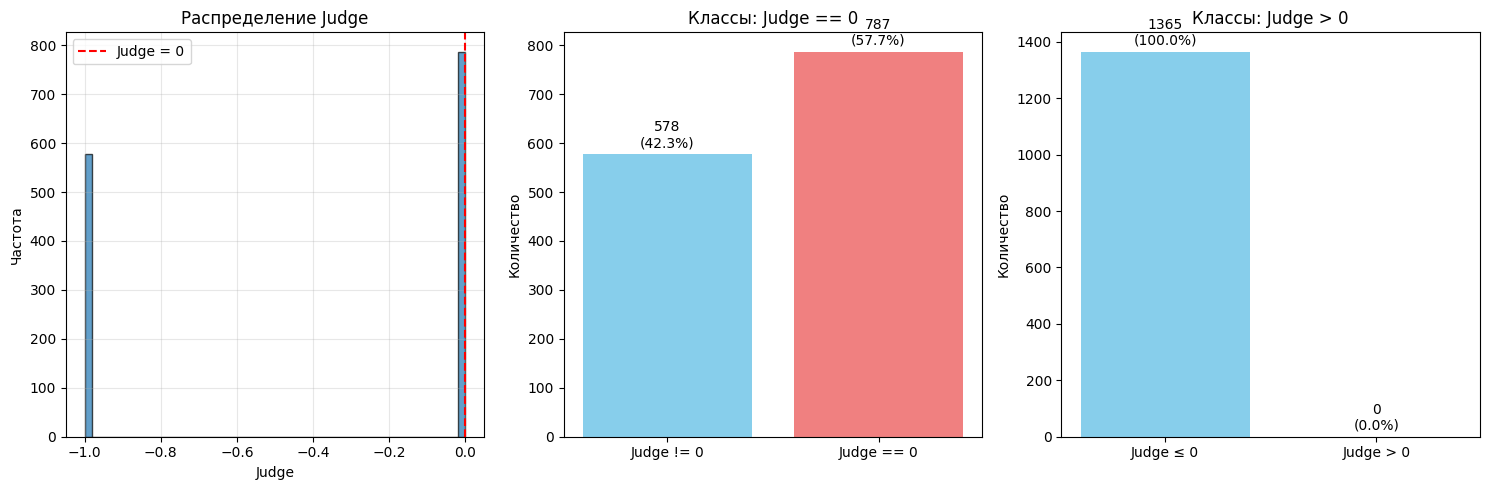


РЕКОМЕНДАЦИИ ПО ВЫБОРУ ПОРОГА
Распределение разумное. Можно использовать Judge == 0 как порог.

Используемая бинаризация:
  Класс 1: 787 примеров (57.7%)
  Класс 0: 578 примеров (42.3%)


In [149]:
# Проверка распределения классов
print("=" * 80)
print("АНАЛИЗ РАСПРЕДЕЛЕНИЯ КЛАССОВ")
print("=" * 80)

y=photo_df['Judge']


y=photo_df['Judge'].values
df=photo_df.drop(columns=["Judge"])
len(df.columns)
X=df.values

# Ваш текущий подход: Judge == 0
y_binary_eq = (y == 0).astype(int)
print("Текущая бинаризация (Judge == 0):")
print(f"  Класс 1 (Judge == 0): {(y_binary_eq == 1).sum()} примеров ({(y_binary_eq == 1).sum()/len(y):.1%})")
print(f"  Класс 0 (Judge != 0): {(y_binary_eq == 0).sum()} примеров ({(y_binary_eq == 0).sum()/len(y):.1%})")

# Альтернативный подход: Judge > 0
y_binary_gt = (y > 0).astype(int)
print("\nАльтернативная бинаризация (Judge > 0):")
print(f"  Класс 1 (Judge > 0): {(y_binary_gt == 1).sum()} примеров ({(y_binary_gt == 1).sum()/len(y):.1%})")
print(f"  Класс 0 (Judge ≤ 0): {(y_binary_gt == 0).sum()} примеров ({(y_binary_gt == 0).sum()/len(y):.1%})")

# Анализ значений Judge
print("\nСтатистика значений Judge:")
print(f"  Минимум: {y.min()}")
print(f"  Максимум: {y.max()}")
print(f"  Среднее: {y.mean():.2f}")
print(f"  Медиана: {np.median(y):.2f}")
print(f"  Уникальные значения: {len(np.unique(y))}")

# Проверяем, сколько Judge = 0
zero_count = np.sum(y == 0)
print(f"\nКоличество Judge = 0: {zero_count} ({(zero_count/len(y)*100):.1f}%)")

# Проверяем, сколько Judge > 0
positive_count = np.sum(y > 0)
print(f"Количество Judge > 0: {positive_count} ({(positive_count/len(y)*100):.1f}%)")

# Проверяем, сколько Judge < 0  
negative_count = np.sum(y < 0)
print(f"Количество Judge < 0: {negative_count} ({(negative_count/len(y)*100):.1f}%)")


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Гистограмма Judge
axes[0].hist(y, bins=50, edgecolor='black', alpha=0.7)
axes[0].axvline(x=0, color='red', linestyle='--', label='Judge = 0')
axes[0].set_title('Распределение Judge')
axes[0].set_xlabel('Judge')
axes[0].set_ylabel('Частота')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Распределение классов при Judge == 0
class_counts_eq = [np.sum(y_binary_eq == 0), np.sum(y_binary_eq == 1)]
axes[1].bar(['Judge != 0', 'Judge == 0'], class_counts_eq, color=['skyblue', 'lightcoral'])
axes[1].set_title('Классы: Judge == 0')
axes[1].set_ylabel('Количество')
for i, v in enumerate(class_counts_eq):
    axes[1].text(i, v + max(class_counts_eq)*0.01, f'{v}\n({v/len(y)*100:.1f}%)', 
                ha='center', va='bottom')

# Распределение классов при Judge > 0
class_counts_gt = [np.sum(y_binary_gt == 0), np.sum(y_binary_gt == 1)]
axes[2].bar(['Judge ≤ 0', 'Judge > 0'], class_counts_gt, color=['skyblue', 'lightcoral'])
axes[2].set_title('Классы: Judge > 0')
axes[2].set_ylabel('Количество')
for i, v in enumerate(class_counts_gt):
    axes[2].text(i, v + max(class_counts_gt)*0.01, f'{v}\n({v/len(y)*100:.1f}%)', 
                ha='center', va='bottom')

plt.tight_layout()
plt.show()

# Рекомендация по выбору порога
print("\n" + "=" * 80)
print("РЕКОМЕНДАЦИИ ПО ВЫБОРУ ПОРОГА")
print("=" * 80)

if zero_count < 0.05 * len(y):  # Меньше 5% нулей
    print("СЛИШКОМ МАЛО Judge = 0! Логистическая регрессия может не сходиться.")
    print("Рекомендация: использовать Judge > 0 как порог")
    y_binary = y_binary_gt
elif zero_count > 0.95 * len(y):  # Больше 95% нулей
    print("СЛИШКОМ МНОГО Judge = 0! Логистическая регрессия может не сходиться.")
    print("Рекомендация: использовать Judge > 0 как порог")
    y_binary = y_binary_gt
else:
    print("Распределение разумное. Можно использовать Judge == 0 как порог.")
    y_binary = y_binary_eq

print(f"\nИспользуемая бинаризация:")
print(f"  Класс 1: {np.sum(y_binary == 1)} примеров ({(np.sum(y_binary == 1)/len(y)*100):.1f}%)")
print(f"  Класс 0: {np.sum(y_binary == 0)} примеров ({(np.sum(y_binary == 0)/len(y)*100):.1f}%)")

In [150]:
photo_df.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin
count,1365.000000,1365.000000,1365.000000,1365.000000,1365.000000,1365.000000
mean,-0.423443,0.437098,0.787408,0.523674,0.885232,0.019889
std,0.494285,0.106001,0.275690,0.023233,0.291257,0.032399
min,-1.000000,0.192773,0.000000,0.361911,0.000000,0.000000
25%,-1.000000,0.352407,0.762189,0.509235,0.974453,0.001534
50%,0.000000,0.490385,0.895274,0.523379,0.998905,0.003567
75%,0.000000,0.508416,0.947015,0.538596,1.000000,0.027267
max,0.000000,0.601727,0.997512,0.594466,1.000000,0.143493


# Обучение модели 
Применяем готовую библиотеку Sklearn

In [151]:


df_X=photo_df.drop(columns='Judge')
X=df_X.values
df_y=photo_df['Judge']
y=df_y.values


In [152]:
#Разбивка выборки


X_train,X_test,y_train,y_test=model_selection.train_test_split(X,y,test_size=0.3,random_state=15)
df_y_train=pd.DataFrame(y_train)
df_y_test=pd.DataFrame(y_test)
print(df_y_train.value_counts())
print(df_y_test.value_counts())

0 
 0    554
-1    401
Name: count, dtype: int64
0 
 0    233
-1    177
Name: count, dtype: int64


In [153]:
clf = LogisticRegression(random_state=42,max_iter=100000,solver='newton-cholesky',C=1).fit(X_train, y_train)
clf.fit(X_train,y_train)
y_pred_test=clf.predict(X_test)



In [154]:

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

TN: 164
FP: 13
FN: 0
TP: 233


In [155]:


# 1. Получаем вероятности от обученной модели
y_pred = clf.predict_proba(X_test)[:, 1]  # вероятности для класса 1

# 2. Выбираем свой порог
my_threshold = 0.595 # например, смещаем вниз

# 3. Получаем предсказания с новым порогом
y_pred = np.where(y_pred >= my_threshold, 0, -1)

# 4. Считаем матрицу ошибок
cm = confusion_matrix(y_test, y_pred)
print("Матрица ошибок:")
print(cm)

# 5. Извлекаем значения (если нужно по отдельности)
tn, fp, fn, tp = cm.ravel()
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)


precision = precision_score(y_test, y_pred, pos_label=0)
recall = recall_score(y_test, y_pred, pos_label=0)
f1 = f1_score(y_test, y_pred, pos_label=0)

print(f"Precision (Точность): {precision:.4f}")
print(f"Recall (Полнота):     {recall:.4f}")
print(f"F1-Score:             {f1:.4f}\n")

Матрица ошибок:
[[168   9]
 [  0 233]]
TN: 168
FP: 9
FN: 0
TP: 233
Precision (Точность): 0.9628
Recall (Полнота):     1.0000
F1-Score:             0.9811



Для реального производства, в моём случае было важнее сохранить, чтоб у нас был как можно меньше ложно негативных срабатываний т.е. минимизировать случаи не брак помечается как брак. На ячейке кода можно отработать этот порог вероятности. Который и будет ориентиром для настройки в камере Omron FQ2.

# Метрики

In [156]:
clf.score(X_test, y_test)

0.9682926829268292

In [157]:
clf.score(X, y)

0.9684981684981685

In [158]:


# Define the number of folds for cross-validation
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=15)

In [159]:


scores = cross_val_score(clf, X, y, cv=kf)
print(scores)

[0.967  0.9707 0.978  0.9597 0.9744]


In [160]:
mean_scores=np.mean(scores)
print(mean_scores)

0.9699633699633698


# обучение на всём датасете

In [161]:
clf.fit(X,y)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multicl

In [162]:
coef=clf.coef_
intercept=clf.intercept_
full_params=np.concatenate([intercept.reshape(-1,1),coef],axis=1)
print(coef)
print(intercept)
print(full_params)
y_pred=clf.predict(X)

[[12.2732  7.8835 -1.8909  2.0263 -3.4869]]
[-12.3326]
[[-12.3326  12.2732   7.8835  -1.8909   2.0263  -3.4869]]


In [163]:
print(y_pred)
print(y)

accuracy = accuracy_score(y, y_pred)
precision = precision_score(y, y_pred,pos_label=0)
recall = recall_score(y, y_pred,pos_label=0)
f1 = f1_score(y, y_pred,pos_label=0)
print(f'Accuracy: {accuracy}')
print(f'Precision: {precision}')
print(f'Recall: {recall}')
print(f'F1-score: {f1}')

[ 0 -1  0 ...  0  0  0]
[ 0 -1  0 ...  0  0  0]
Accuracy: 0.9714285714285714
Precision: 0.9527845036319612
Recall: 1.0
F1-score: 0.9758214507129572


In [164]:

tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

TN: 539
FP: 39
FN: 0
TP: 787


In [165]:
len(X)
def sigmoid(z):
    """Сигмоидная функция активации"""
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [166]:

X1 = np.append(np.ones((len(X), 1)), X, axis=1)
Y=X1@full_params.T



for ind in range(len(Y)):
    print(f"Значение {Y[ind]} Значение sigma {sigmoid(Y[ind])} Значение DataFrame {y[ind]}")
print(Y.shape)


Значение [1.3965] Значение sigma [0.8016] Значение DataFrame 0
Значение [-3.0381] Значение sigma [0.0457] Значение DataFrame -1
Значение [2.0185] Значение sigma [0.8827] Значение DataFrame 0
Значение [-2.5597] Значение sigma [0.0718] Значение DataFrame -1
Значение [2.928] Значение sigma [0.9492] Значение DataFrame 0
Значение [2.7654] Значение sigma [0.9408] Значение DataFrame 0
Значение [-1.7172] Значение sigma [0.1522] Значение DataFrame -1
Значение [1.2799] Значение sigma [0.7824] Значение DataFrame 0
Значение [1.8211] Значение sigma [0.8607] Значение DataFrame 0
Значение [2.9065] Значение sigma [0.9482] Значение DataFrame 0
Значение [-0.5794] Значение sigma [0.3591] Значение DataFrame -1
Значение [-2.2191] Значение sigma [0.098] Значение DataFrame -1
Значение [-3.1965] Значение sigma [0.0393] Значение DataFrame -1
Значение [2.3588] Значение sigma [0.9136] Значение DataFrame 0
Значение [2.3146] Значение sigma [0.9101] Значение DataFrame 0
Значение [-1.2996] Значение sigma [0.2142] Зн

In [167]:
series_Y=pd.Series(Y.flatten())
series_Sigma=pd.Series(sigmoid(Y).flatten())
series_df=pd.Series(y.flatten())
df_sumary_prediction=pd.DataFrame(
    {
        "Значение по коэфициентам": series_Y, 
        "Значение Sigma": series_Sigma,
        "Значение DataFrame": series_df
    }
)

df_sumary_prediction.describe()


,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,1365.000000,1365.000000,1365.000000
mean,-0.026273,0.576557,-0.423443
std,3.062513,0.385459,0.494285
min,-7.141415,0.000791,-1.000000
25%,-2.112718,0.107867,-1.000000
50%,1.631155,0.836328,0.000000
75%,2.332979,0.911572,0.000000
max,3.250011,0.962674,0.000000


In [168]:
fig = px.scatter(df_sumary_prediction, y=['Значение по коэфициентам',	'Значение Sigma',	'Значение DataFrame'])
fig.show()



In [169]:
df_sumary_prediction_small_treshhold=df_sumary_prediction[(df_sumary_prediction['Значение по коэфициентам']<0) & (df_sumary_prediction['Значение DataFrame']==-1) ]
df_sumary_prediction_small_treshhold.describe()

,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,539.000000,539.000000,539.0
mean,-3.294476,0.117167,-1.0
std,2.347743,0.129497,0.0
min,-7.141415,0.000791,-1.0
25%,-4.514628,0.010831,-1.0
50%,-2.711717,0.062286,-1.0
75%,-1.453355,0.189488,-1.0
max,-0.023739,0.494066,-1.0


In [170]:
df_sumary_prediction_small_treshhold=df_sumary_prediction[(df_sumary_prediction['Значение по коэфициентам']<0) & (df_sumary_prediction['Значение DataFrame']==0) ]
df_sumary_prediction_small_treshhold.describe()

,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,0.0,0.0,0.0
mean,NaN,NaN,NaN
std,NaN,NaN,NaN
min,NaN,NaN,NaN
25%,NaN,NaN,NaN
50%,NaN,NaN,NaN
75%,NaN,NaN,NaN
max,NaN,NaN,NaN


In [171]:
df_sumary_prediction_small_treshhold=df_sumary_prediction[(df_sumary_prediction['Значение по коэфициентам']<-1.7) & (df_sumary_prediction["Значение DataFrame"]==-1) ]
df_sumary_prediction_small_treshhold.describe()

,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,373.000000,373.000000,373.0
mean,-4.338313,0.041186,-1.0
std,2.080949,0.040544,0.0
min,-7.141415,0.000791,-1.0
25%,-7.141415,0.000791,-1.0
50%,-3.259962,0.036971,-1.0
75%,-2.641814,0.066495,-1.0
max,-1.717178,0.152235,-1.0


In [172]:
df_sumary_prediction.describe()

,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,1365.000000,1365.000000,1365.000000
mean,-0.026273,0.576557,-0.423443
std,3.062513,0.385459,0.494285
min,-7.141415,0.000791,-1.000000
25%,-2.112718,0.107867,-1.000000
50%,1.631155,0.836328,0.000000
75%,2.332979,0.911572,0.000000
max,3.250011,0.962674,0.000000


In [173]:
photo_df_summary=pd.concat([photo_df,df_sumary_prediction],join='inner',axis=1)
photo_df_summary.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,1365.000000,1365.000000,1365.000000,1365.000000,1365.000000,1365.000000,1365.000000,1365.000000,1365.000000
mean,-0.423443,0.437098,0.787408,0.523674,0.885232,0.019889,-0.026273,0.576557,-0.423443
std,0.494285,0.106001,0.275690,0.023233,0.291257,0.032399,3.062513,0.385459,0.494285
min,-1.000000,0.192773,0.000000,0.361911,0.000000,0.000000,-7.141415,0.000791,-1.000000
25%,-1.000000,0.352407,0.762189,0.509235,0.974453,0.001534,-2.112718,0.107867,-1.000000
50%,0.000000,0.490385,0.895274,0.523379,0.998905,0.003567,1.631155,0.836328,0.000000
75%,0.000000,0.508416,0.947015,0.538596,1.000000,0.027267,2.332979,0.911572,0.000000
max,0.000000,0.601727,0.997512,0.594466,1.000000,0.143493,3.250011,0.962674,0.000000


In [174]:
fig = px.scatter(photo_df_summary, y=['P0.CR',	'Значение Sigma',	'Значение DataFrame', 'Значение по коэфициентам'])

fig.show()

In [175]:
df_sumary_prediction_small_treshhold_NG=photo_df_summary[
                                                            
                                                            (photo_df_summary['Значение DataFrame']==-1) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold_NG.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,578.0,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.0
mean,-1.0,0.347472,0.595219,0.529865,0.733589,0.042237,-3.038309,0.151028,-1.0
std,0.0,0.109499,0.335115,0.032035,0.400664,0.039911,2.460949,0.178685,0.0
min,-1.0,0.192773,0.000000,0.361911,0.000000,0.000000,-7.141415,0.000791,-1.0
25%,-1.0,0.252776,0.587189,0.500000,0.766788,0.001301,-4.032074,0.017429,-1.0
50%,-1.0,0.328425,0.732090,0.538687,0.951095,0.034284,-2.570077,0.071090,-1.0
75%,-1.0,0.500000,0.814241,0.550219,1.000000,0.068600,-1.153487,0.239856,-1.0
max,-1.0,0.601727,0.980597,0.594466,1.000000,0.143493,1.424709,0.806076,-1.0


In [176]:
df_sumary_prediction_small_treshhold_OK=photo_df_summary[
                                                            
                                                            (photo_df_summary['Значение DataFrame']==0) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold_OK.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,787.0,787.000000,787.000000,787.000000,787.000000,787.000000,787.000000,787.000000,787.0
mean,0.0,0.502923,0.928559,0.519127,0.996604,0.003475,2.185870,0.889080,0.0
std,0.0,0.021247,0.048422,0.011595,0.006056,0.003897,0.508709,0.058725,0.0
min,0.0,0.450492,0.781841,0.498937,0.971898,0.000000,0.412950,0.601795,0.0
25%,0.0,0.486058,0.910448,0.509826,0.996350,0.001562,1.922893,0.872461,0.0
50%,0.0,0.502572,0.939303,0.517171,1.000000,0.002794,2.257022,0.905255,0.0
75%,0.0,0.519695,0.962935,0.528062,1.000000,0.004317,2.552180,0.927720,0.0
max,0.0,0.550030,0.997512,0.542012,1.000000,0.027267,3.250011,0.962674,0.0


In [177]:
fig=px.box(df_sumary_prediction_small_treshhold_OK)
fig.show()

In [178]:
fig=px.box(df_sumary_prediction_small_treshhold_NG)
fig.show()

# Параметры модели

In [179]:
np.set_printoptions(precision=4, suppress=True)
print(full_params)

[[-12.3326  12.2732   7.8835  -1.8909   2.0263  -3.4869]]


In [180]:
photo_df_summary.value_counts

<bound method DataFrame.value_counts of       Judge     P0.DY     P0.CR     P1.DY     P1.CR  P1.angle_sin  \
0         0  0.465277  0.883831  0.510914  1.000000      0.002639   
1        -1  0.233649  0.733333  0.540809  0.875912      0.030586   
2         0  0.489124  0.923881  0.506891  1.000000      0.000946   
3        -1  0.237713  0.769900  0.503696  0.974453      0.067735   
4         0  0.529905  0.978358  0.514358  0.999635      0.002560   
...     ...       ...       ...       ...       ...           ...   
1360     -1  0.409071  0.685323  0.554115  0.989051      0.069988   
1361      0  0.484601  0.954229  0.526851  0.996350      0.005248   
1362      0  0.527463  0.932338  0.515732  1.000000      0.000000   
1363      0  0.494484  0.939303  0.516236  1.000000      0.004295   
1364      0  0.499004  0.937562  0.509614  0.996350      0.003583   

      Значение по коэфициентам  Значение Sigma  Значение DataFrame  
0                     1.396544        0.801635                

In [181]:
df_sumary_prediction_small_treshhold_NG=photo_df_summary[
                                                            
                                                            (photo_df_summary['Значение DataFrame']==-1) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold_NG.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,578.0,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.0
mean,-1.0,0.347472,0.595219,0.529865,0.733589,0.042237,-3.038309,0.151028,-1.0
std,0.0,0.109499,0.335115,0.032035,0.400664,0.039911,2.460949,0.178685,0.0
min,-1.0,0.192773,0.000000,0.361911,0.000000,0.000000,-7.141415,0.000791,-1.0
25%,-1.0,0.252776,0.587189,0.500000,0.766788,0.001301,-4.032074,0.017429,-1.0
50%,-1.0,0.328425,0.732090,0.538687,0.951095,0.034284,-2.570077,0.071090,-1.0
75%,-1.0,0.500000,0.814241,0.550219,1.000000,0.068600,-1.153487,0.239856,-1.0
max,-1.0,0.601727,0.980597,0.594466,1.000000,0.143493,1.424709,0.806076,-1.0


In [182]:
df_sumary_prediction_small_treshhold_OK=photo_df_summary[
                                                            
                                                            (photo_df_summary['Значение DataFrame']==0) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold_OK.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,787.0,787.000000,787.000000,787.000000,787.000000,787.000000,787.000000,787.000000,787.0
mean,0.0,0.502923,0.928559,0.519127,0.996604,0.003475,2.185870,0.889080,0.0
std,0.0,0.021247,0.048422,0.011595,0.006056,0.003897,0.508709,0.058725,0.0
min,0.0,0.450492,0.781841,0.498937,0.971898,0.000000,0.412950,0.601795,0.0
25%,0.0,0.486058,0.910448,0.509826,0.996350,0.001562,1.922893,0.872461,0.0
50%,0.0,0.502572,0.939303,0.517171,1.000000,0.002794,2.257022,0.905255,0.0
75%,0.0,0.519695,0.962935,0.528062,1.000000,0.004317,2.552180,0.927720,0.0
max,0.0,0.550030,0.997512,0.542012,1.000000,0.027267,3.250011,0.962674,0.0


In [183]:
fig=px.box(df_sumary_prediction_small_treshhold_OK,title="OK")
fig.show()

In [184]:
fig=px.box(df_sumary_prediction_small_treshhold_NG,title='NG')
fig.show()

In [185]:
df_sumary_prediction_small_treshhold=df_sumary_prediction[(df_sumary_prediction['Значение по коэфициентам']<1.5) & (df_sumary_prediction['Значение DataFrame']==-1) ]
df_sumary_prediction_small_treshhold.describe()

,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,578.000000,578.000000,578.0
mean,-3.038309,0.151028,-1.0
std,2.460949,0.178685,0.0
min,-7.141415,0.000791,-1.0
25%,-4.032074,0.017429,-1.0
50%,-2.570077,0.071090,-1.0
75%,-1.153487,0.239856,-1.0
max,1.424709,0.806076,-1.0


In [186]:
df_sumary_prediction_small_treshhold=df_sumary_prediction[(df_sumary_prediction['Значение по коэфициентам']<-2.13) & (df_sumary_prediction['Значение DataFrame']==0) ]
df_sumary_prediction_small_treshhold.describe()

,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,0.0,0.0,0.0
mean,NaN,NaN,NaN
std,NaN,NaN,NaN
min,NaN,NaN,NaN
25%,NaN,NaN,NaN
50%,NaN,NaN,NaN
75%,NaN,NaN,NaN
max,NaN,NaN,NaN


In [187]:
df_sumary_prediction_small_treshhold=df_sumary_prediction[(df_sumary_prediction['Значение по коэфициентам']<-2.13) ]
df_sumary_prediction_small_treshhold.describe()

,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,339.000000,339.000000,339.0
mean,-4.578942,0.032645,-1.0
std,2.031596,0.031446,0.0
min,-7.141415,0.000791,-1.0
25%,-7.141415,0.000791,-1.0
50%,-3.496265,0.029419,-1.0
75%,-2.813005,0.056625,-1.0
max,-2.153044,0.104047,-1.0


In [188]:
photo_df_summary=pd.concat([photo_df,df_sumary_prediction],join='inner',axis=1)
photo_df_summary.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,1365.000000,1365.000000,1365.000000,1365.000000,1365.000000,1365.000000,1365.000000,1365.000000,1365.000000
mean,-0.423443,0.437098,0.787408,0.523674,0.885232,0.019889,-0.026273,0.576557,-0.423443
std,0.494285,0.106001,0.275690,0.023233,0.291257,0.032399,3.062513,0.385459,0.494285
min,-1.000000,0.192773,0.000000,0.361911,0.000000,0.000000,-7.141415,0.000791,-1.000000
25%,-1.000000,0.352407,0.762189,0.509235,0.974453,0.001534,-2.112718,0.107867,-1.000000
50%,0.000000,0.490385,0.895274,0.523379,0.998905,0.003567,1.631155,0.836328,0.000000
75%,0.000000,0.508416,0.947015,0.538596,1.000000,0.027267,2.332979,0.911572,0.000000
max,0.000000,0.601727,0.997512,0.594466,1.000000,0.143493,3.250011,0.962674,0.000000


In [189]:
fig = px.scatter(photo_df_summary, y=['P0.CR',	'Значение Sigma',	'Значение DataFrame', 'Значение по коэфициентам'])

fig.show()

In [190]:
df_sumary_prediction_small_treshhold1=photo_df_summary[
                                                            (photo_df_summary['Значение по коэфициентам']<-1	) &
                                                            (photo_df_summary['Значение DataFrame']==0) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold1.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [191]:
df_sumary_prediction_small_treshhold_NG=photo_df_summary[
                                                          
                                                            (photo_df_summary['Значение DataFrame']==-1) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold_NG.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,578.0,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.0
mean,-1.0,0.347472,0.595219,0.529865,0.733589,0.042237,-3.038309,0.151028,-1.0
std,0.0,0.109499,0.335115,0.032035,0.400664,0.039911,2.460949,0.178685,0.0
min,-1.0,0.192773,0.000000,0.361911,0.000000,0.000000,-7.141415,0.000791,-1.0
25%,-1.0,0.252776,0.587189,0.500000,0.766788,0.001301,-4.032074,0.017429,-1.0
50%,-1.0,0.328425,0.732090,0.538687,0.951095,0.034284,-2.570077,0.071090,-1.0
75%,-1.0,0.500000,0.814241,0.550219,1.000000,0.068600,-1.153487,0.239856,-1.0
max,-1.0,0.601727,0.980597,0.594466,1.000000,0.143493,1.424709,0.806076,-1.0


In [192]:
df_sumary_prediction_small_treshhold_OK_stat=photo_df_summary[ (photo_df_summary['Значение Sigma']>0.595
                                                                )&
                                                            
                                                            (photo_df_summary['Значение DataFrame']==0) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold_OK_stat.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,787.0,787.000000,787.000000,787.000000,787.000000,787.000000,787.000000,787.000000,787.0
mean,0.0,0.502923,0.928559,0.519127,0.996604,0.003475,2.185870,0.889080,0.0
std,0.0,0.021247,0.048422,0.011595,0.006056,0.003897,0.508709,0.058725,0.0
min,0.0,0.450492,0.781841,0.498937,0.971898,0.000000,0.412950,0.601795,0.0
25%,0.0,0.486058,0.910448,0.509826,0.996350,0.001562,1.922893,0.872461,0.0
50%,0.0,0.502572,0.939303,0.517171,1.000000,0.002794,2.257022,0.905255,0.0
75%,0.0,0.519695,0.962935,0.528062,1.000000,0.004317,2.552180,0.927720,0.0
max,0.0,0.550030,0.997512,0.542012,1.000000,0.027267,3.250011,0.962674,0.0


In [193]:
df_sumary_prediction_small_treshhold_NG_stat=photo_df_summary[(photo_df_summary['Значение Sigma']<=0.595)&
                                                            
                                                            (photo_df_summary['Значение DataFrame']==-1) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold_NG_stat.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,558.0,558.000000,558.000000,558.000000,558.000000,558.000000,558.000000,558.000000,558.0
mean,-1.0,0.344407,0.584941,0.529278,0.724812,0.042628,-3.174980,0.132020,-1.0
std,0.0,0.109623,0.336139,0.032390,0.405016,0.040158,2.393770,0.149980,0.0
min,-1.0,0.192773,0.000000,0.361911,0.000000,0.000000,-7.141415,0.000791,-1.0
25%,-1.0,0.249641,0.564615,0.500000,0.754106,0.001004,-4.220635,0.014486,-1.0
50%,-1.0,0.315642,0.727239,0.538193,0.945256,0.034519,-2.641865,0.066492,-1.0
75%,-1.0,0.500000,0.802923,0.550215,1.000000,0.068841,-1.321696,0.210537,-1.0
max,-1.0,0.547725,0.980597,0.594466,1.000000,0.143493,0.366046,0.590503,-1.0


# Финальная формула для интеграции в смарт-камеру / ПЛК
 Модель использует порог вероятности 0.5, что соответствует значению 0 для линейного уравнения.
 Если Результат >= 0 -> Годный объект (0)
 Если Результат <  0 -> Брак (-1)

In [194]:

features = ["('P0.DY'+100)/(100+100)", "'P0.CR'/100", "('P1.DY'+100)/(100+100)", "'P1.CR'/100", "ABS(SIN('P1.TH')"]
equation = f"Результат = {clf.intercept_[0]:.4f}"

for coef, feat in zip(clf.coef_[0], features):
    sign = "+" if coef >= 0 else "-"
    equation += f" {sign} {abs(coef):.4f} * {feat}"

print(equation)

Результат = -12.3326 + 12.2732 * ('P0.DY'+100)/(100+100) + 7.8835 * 'P0.CR'/100 - 1.8909 * ('P1.DY'+100)/(100+100) + 2.0263 * 'P1.CR'/100 - 3.4869 * ABS(SIN('P1.TH')
